# Workers and the work calendar

Instance `data/instances/toy-workshop.json` (model in `math/04_workers.md`): a printer, an oven and a mill, two
workers A and B, the default calendar (shift 08:00–17:30, break of 60 minutes starting 12:00–13:00, up to 120
minutes of overtime, shipping cutoff 12:00, Monday to Friday; t = 0 is Monday 08:00). Eight orders with due dates at
the Monday or Tuesday cutoff. Worker shares:
- print and mill: the loading (prefix) by a worker, the rest unattended; a print may run into the night;
- oven: loading and removal (prefix and suffix); the only operation with a pending removal (C7$^o$);
- Gegenbetten of k3: 30 minutes by a worker, then the rest without a worker (unattended rest);
- QM: the whole operation, only by A; packing: the whole operation, by A or B.

k7 (QM released 15:30) and k8 (QM released Tuesday 08:00) are both due Tuesday 12:00 and both need A: k7's QM
either runs into overtime on Monday or one of the two misses Tuesday's cutoff. **A hand-made toy instance, not
Fidentis data.**

In [1]:
%matplotlib inline
from fractions import Fraction
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt

import simulation
from simulation.check.feasibility import check_schedule
from simulation.control.rescheduling import ReschedulingPolicy, execute
from simulation.io.json_loader import read_model
from simulation.metrics import run_metrics
from simulation.model.compiled import compile_instance
from simulation.model.instance import Instance
from simulation.objectives import (
    ACTIVE_MAKESPAN,
    BREAK_PENALTY,
    MAKESPAN,
    TOTAL_TARDINESS,
    cutoff_slack,
    overtime,
    worker_objective,
    worker_objective_with_slack,
)
from simulation.planners.cpsat import cpsat_planner, solve
from simulation.planners.dispatching import ASSIGNMENT_RULES, SEQUENCING_RULES, dispatch_plan, dispatch_planner
from simulation.sim.scenario import sample_scenario
from simulation.viz import plot_days, plot_shifts

DATA = Path(simulation.__file__).parents[2] / "data"
inst = read_model(DATA / "instances" / "toy-workshop.json", Instance)
ci = compile_instance(inst)
THETA = Fraction(1, 60)  # 60 minutes of overtime are worth one day late
objective = worker_objective(THETA)

## Plans

The worker objective (`math/04_workers.md` (O4)–(O6)), lexicographic: (1) days late + $\theta_O$ × overtime minutes,
$\theta_O = 1/60$; (2) break postponement and spread; (3) the activity clock $C^{act}_{\max}$ (time in the shifts,
plus time outside them while an operation is in progress). Best of the 15 dispatching rules under this objective
against CP-SAT (level by level, 20 s per level).

In [2]:
rules = {f"{s}/{a or 'joint'}": dispatch_plan(ci, SEQUENCING_RULES[s], ASSIGNMENT_RULES[a] if a else None)
         for s in SEQUENCING_RULES for a in [*ASSIGNMENT_RULES, None]}
rule = min(rules, key=lambda name: objective.evaluate(ci, rules[name].assignments, rules[name].breaks))
rule_plan = rules[rule]
cp = solve(ci, objective, time_limit=60, workers=1, deterministic_time=20)  # one thread: reproducible start plan
print(f"CP-SAT: {cp.status}, level values {cp.levels}, {cp.wall_time:.1f} s")
print(f"{'plan':30} {'days late':>9} {'overtime':>9} {'breaks':>7} {'Cmax':>6} {'C_act':>6} {'violations':>11}")
for name, schedule, breaks in [(f"best rule ({rule})", rule_plan.assignments, rule_plan.breaks),
                               ("CP-SAT", cp.schedule, cp.breaks)]:
    print(f"{name:30} {TOTAL_TARDINESS.evaluate(ci, schedule):>9} {overtime(ci, schedule):>9}"
          f" {BREAK_PENALTY.evaluate(ci, schedule, breaks):>7} {MAKESPAN.evaluate(ci, schedule):>6}"
          f" {ACTIVE_MAKESPAN.evaluate(ci, schedule):>6} {len(check_schedule(ci, schedule, breaks=breaks)):>11}")

CP-SAT: OPTIMAL, level values (30, 0, 920), 0.1 s
plan                           days late  overtime  breaks   Cmax  C_act  violations
best rule (mwkr/least_load)            1         0       0   1910   1190           0
CP-SAT                                 0        30       0   1640    920           0


### Resources (machines, workers, unattended rest)

One row per machine and worker, and a row "rest" for the unattended time of machine-less operations. A machine bar is
outlined (unattended) with the worker time in its lower half. Colors encode the state: attended, unattended,
overtime, break; nights and days off are hatched and squeezed to 60 minutes (also while a print runs through the
night), the overtime window 17:30–19:30 is tinted, the cutoffs are dashed. First the rule plan, then CP-SAT.

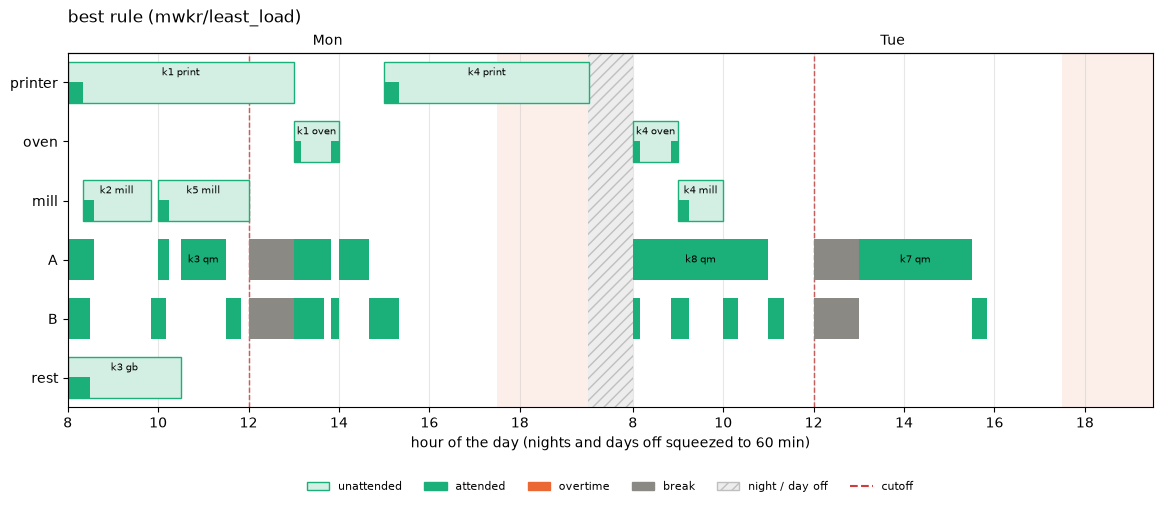

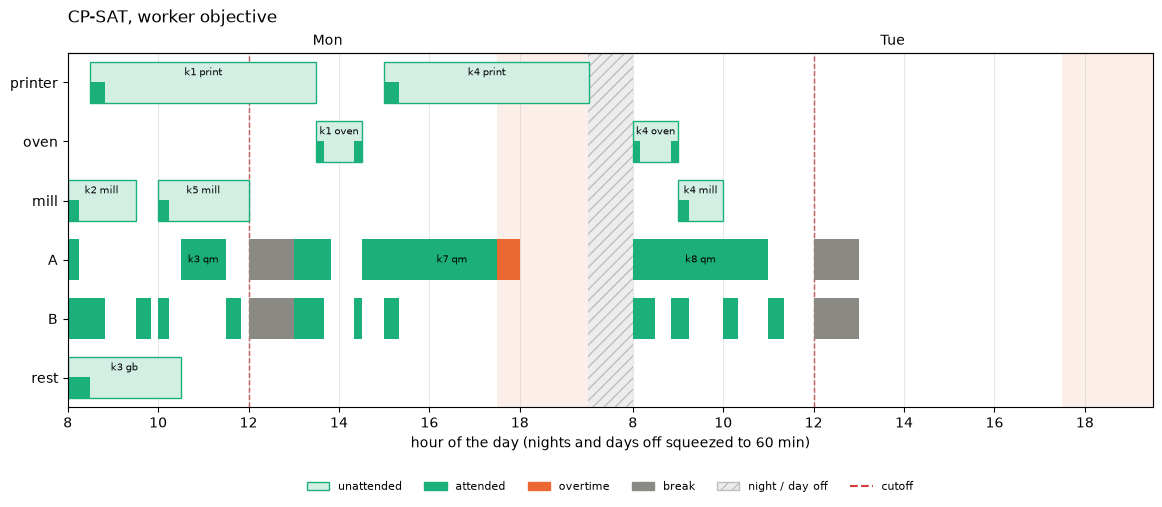

In [3]:
for title, schedule, breaks in [(f"best rule ({rule})", rule_plan.assignments, rule_plan.breaks),
                                ("CP-SAT, worker objective", cp.schedule, cp.breaks)]:
    plot_shifts(ci, schedule, breaks, title=title)
    plt.show()

### Workers only, colored by machine

Each bar is one share of a worker, labeled order, operation and machine. The color names the machine the share
serves (printer, oven, mill), light grey with an outline is work without a machine (QM, packing, Gegenbetten);
overtime is cross-hatched. Unattended machine time is not shown here. Three hues only: coloring by step (six here)
fails the colorblind check of the dataviz validator for neighboring bars, three pass it (`viz.MACHINE_COLORS`).

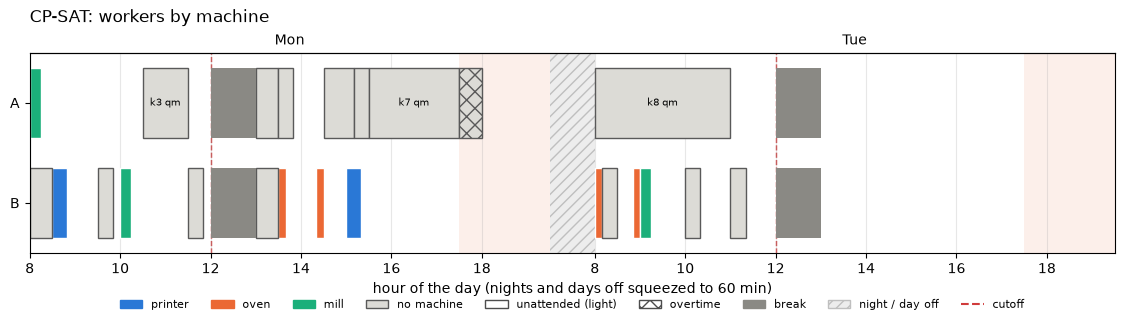

In [4]:
plot_shifts(ci, cp.schedule, cp.breaks, rows="workers", color_by="machine", title="CP-SAT: workers by machine")
plt.show()

### Orders

One row per order: its path through the days, each operation labeled with its workers.

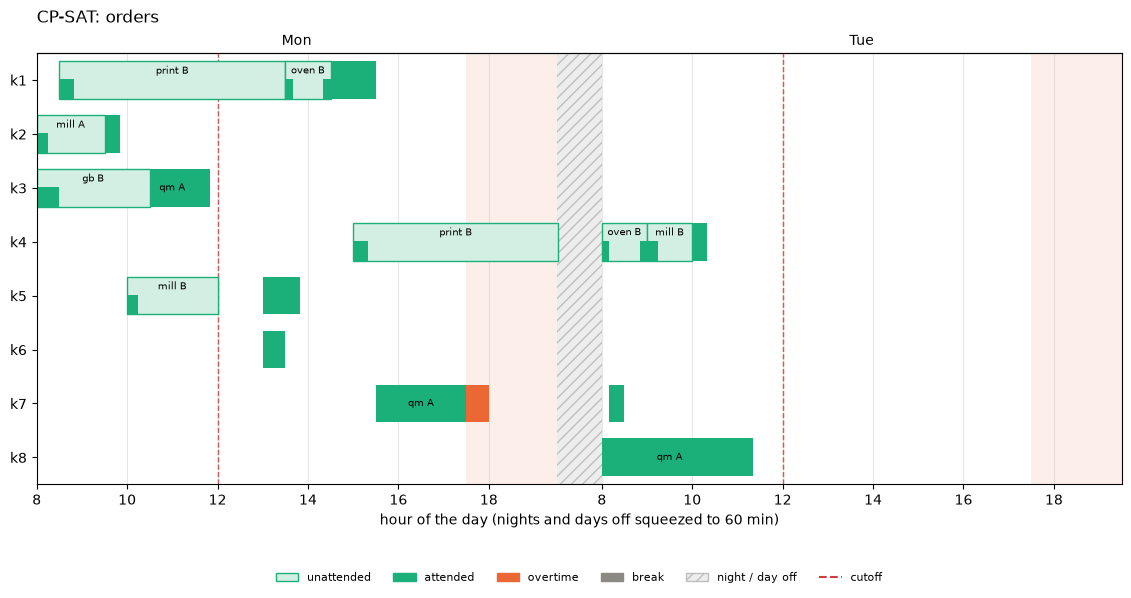

In [5]:
plot_shifts(ci, cp.schedule, cp.breaks, rows="orders", title="CP-SAT: orders")
plt.show()

### Calendar view, three days

One column per day, time of day downward; 08:00–19:30 to scale, the time before and after squeezed to 30 minutes
each. CP-SAT books a break for every working day of its horizon, so Wednesday shows only the breaks.

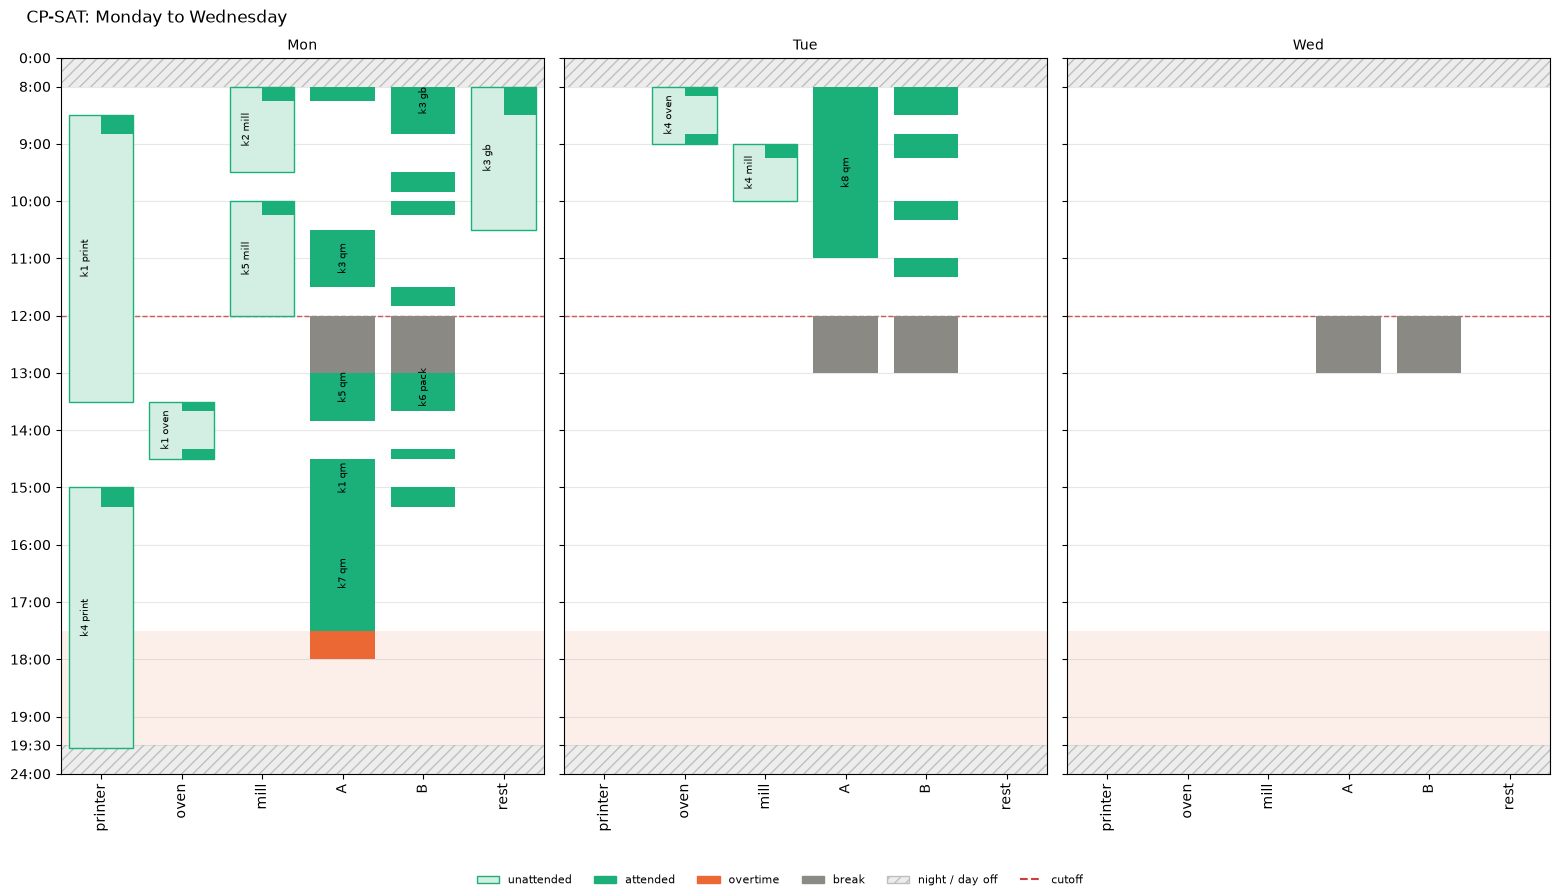

In [6]:
plot_days(ci, cp.schedule, cp.breaks, days=3, title="CP-SAT: Monday to Wednesday")
plt.show()

## Trade-off between overtime and days late ($\theta_O$)

A smaller instance with one exact threshold (the chain of `tests/test_worker_objective.py`): one worker, operation
A (240 minutes) from Monday 15:00, then B (240), due Tuesday 12:00. With 90 minutes of overtime A ends at 19:00 and B
runs Tuesday 08:00–12:00 (on time); without, A runs Tuesday morning and B after the break (one day late). Level 1
weighs one day late against $1/\theta_O$ minutes of overtime: below 90 the plan is late, above 90 it works overtime,
at exactly 90 both have the same value (a tie: the solver may return either). CP-SAT per value of $1/\theta_O$.

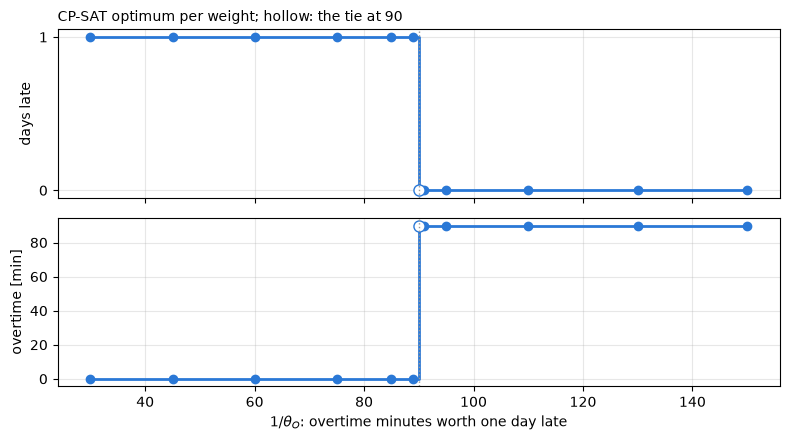

In [7]:
chain = compile_instance(Instance.model_validate({
    "schema_version": "0.6", "name": "chain", "machines": ["M"], "workers": ["W1"], "calendar": {},
    "orders": [{"id": "K", "release": 420, "due_date": 1680, "operations": [
        {"id": "A", "step": "s", "duration": 240, "worker": {"whole": True}},
        {"id": "B", "step": "s", "duration": 240, "worker": {"whole": True}, "predecessors": ["A"]}]}]}))
minutes_per_day = [30, 45, 60, 75, 85, 89, 90, 91, 95, 110, 130, 150]
late, extra = [], []
for m in minutes_per_day:
    r = solve(chain, worker_objective(Fraction(1, m)), time_limit=10, workers=1)
    assert r.status == "OPTIMAL" and check_schedule(chain, r.schedule, breaks=r.breaks) == []
    late.append(TOTAL_TARDINESS.evaluate(chain, r.schedule))
    extra.append(overtime(chain, r.schedule))

fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True)
for ax, values, label in [(top, late, "days late"), (bottom, extra, "overtime [min]")]:
    ax.step(minutes_per_day, values, where="post", color="#2a78d6", linewidth=2)
    ax.plot([m for m in minutes_per_day if m != 90],
            [v for m, v in zip(minutes_per_day, values, strict=True) if m != 90], "o", color="#2a78d6", markersize=6)
    tie = values[minutes_per_day.index(90)]
    ax.plot([90], [tie], "o", markerfacecolor="white", markeredgecolor="#2a78d6", markersize=8)
    ax.axvline(90, color="0.6", linestyle=":", linewidth=1)
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
top.set_yticks([0, 1])
top.set_title("CP-SAT optimum per weight; hollow: the tie at 90", loc="left", fontsize=10)
bottom.set_xlabel(r"$1/\theta_O$: overtime minutes worth one day late")
plt.tight_layout()
plt.show()

## Execution under disturbances

Durations log-normal ($\sigma = 0.3$), start offsets ($q = 0.5$, $a = b = 5$), seeds 0–9. Start plan: the CP-SAT
plan with its breaks (the same for every policy). Policies:
- no planning tool (the factory runs the start plan: each operation as soon as it can, in the planned order);
- repair only, and repair only with the option `repair_overtime` (a moved share may run into overtime up to 19:30,
  as the factory itself would start it; without the option no overtime beyond the plan's, `math/05` §3);
- complete rescheduling with the best rule and with CP-SAT (worker objective, 2 s per level), triggered by
  $\delta_C = 10$, $\delta_S = 30$ and a safety net every 120 minutes (as in notebook 05);
- CP-SAT also with the early-finish trigger $\delta_E = 10$ (an operation finishes at least 10 minutes early while
  the plan still has tardiness or overtime, `math/05` §3), with that trigger and the repair option together, and
  with a safety net every 15 minutes.

Every start and finish of an operation, a worker share or a break is an event for the planning tool (`math/13` §3).
One instance, no statistical test.

Days late are whole days per run (missed cutoffs), so the table gives them as totals over the 10 runs, with the
number of runs that are late at all, and the level-1 value of the worker objective, days late + $\theta_O$ ×
overtime minutes, also summed. The other columns are means per run: makespan $C_{\max}$, activity clock $C^{act}$,
total tardiness $\sum T$ in minutes, then the worker metrics (`math/23_metrics.md`): overtime minutes, overruns past
the overtime window, oven overstay minutes, break postponement and spread, swaps by the factory; $N_C$
reschedulings. "feasible": every realized schedule passes the checker up to C2 (realized durations) and C14 (a break
realized after 13:00, forced by an overrun).

In [8]:
start = cp.schedule
scenarios = [sample_scenario(inst, sigma=0.3, seed=seed, q=0.5, max_early=5, max_late=5) for seed in range(10)]
s, a = rule.split("/")
TRIGGERS = {"max_makespan_change": 10, "max_shift": 30, "period": 120}
policies = {
    "no planning tool": None,
    "repair only": ReschedulingPolicy(),
    "repair only, overtime": ReschedulingPolicy(repair_overtime=True),
    f"rule rescheduling ({rule})": ReschedulingPolicy(
        dispatch_planner(SEQUENCING_RULES[s], ASSIGNMENT_RULES.get(a)), **TRIGGERS),
    "CP-SAT rescheduling": ReschedulingPolicy(cpsat_planner(time_limit=2, objective=objective), **TRIGGERS),
    "CP-SAT + early finish": ReschedulingPolicy(cpsat_planner(time_limit=2, objective=objective), **TRIGGERS,
                                                early_finish=10),
    "CP-SAT + early finish + overtime": ReschedulingPolicy(cpsat_planner(time_limit=2, objective=objective),
                                                           **TRIGGERS, early_finish=10, repair_overtime=True),
    "CP-SAT rescheduling, every 15 min": ReschedulingPolicy(cpsat_planner(time_limit=2, objective=objective),
                                                            **(TRIGGERS | {"period": 15})),
}
means = {"makespan": "Cmax", "active_makespan": "C_act", "total_tardiness": "sum T", "overtime": "overtime",
         "overruns": "overruns", "overstay": "overstay", "break_postponement": "brk post", "break_spread": "spread",
         "swaps": "swaps", "reschedulings": "N_C"}
BUFFER = 60
shortfall = cutoff_slack(BUFFER)


def compare(start, breaks, policies):
    # every policy on the 10 scenarios from one start plan: totals (days late, late runs, level 1 of the theta
    # objective, cutoff shortfall) and means per run; returns the results per policy
    results = {}
    print(f"{'policy':36}{'days':>6}{'late runs':>10}{'level 1':>9}{'short':>7}"
          + "".join(f"{c:>9}" for c in means.values()) + f"{'feasible':>10}")
    for name, policy in policies.items():
        results[name] = [execute(ci, start, sc, policy, breaks=breaks) for sc in scenarios]
        rows = [run_metrics(ci, start, r) for r in results[name]]
        ok = all({v.constraint for v in check_schedule(ci, r.schedule, breaks=r.breaks)} <= {"C2", "C14"}
                 for r in results[name])
        days = [r["tardy_days"] for r in rows]
        level_1 = sum(d + THETA * r["overtime"] for d, r in zip(days, rows, strict=True))
        short = sum(shortfall.evaluate(ci, r.schedule) for r in results[name])
        early = sum("early_finish" in d["triggers"] for r in results[name] for d in r.decisions
                    if d["type"] == "REPLAN")
        print(f"{name:36}{sum(days):>6}{sum(d > 0 for d in days):>10}{float(level_1):>9.2f}{short:>7}"
              + "".join(f"{mean(r[k] for r in rows):>9.1f}" for k in means) + f"{str(ok):>10}")
        print(f"{'':36}days per run: {days}, early-finish replans: {early}")
    return results


results = compare(start, cp.breaks, policies)

policy                                days late runs  level 1  short     Cmax    C_act    sum T overtime overruns overstay brk post   spread    swaps      N_C  feasible
no planning tool                         2         2     9.72    286   1676.3    986.8     23.0     46.3      0.0      9.7     19.8     19.8      1.3      0.0      True
                                    days per run: [0, 0, 1, 1, 0, 0, 0, 0, 0, 0], early-finish replans: 0


repair only                             16         9    18.23    134   1915.5   1191.9    315.8     13.4      0.0      1.0      2.4      2.4      0.9      0.0      True
                                    days per run: [1, 2, 3, 2, 2, 1, 1, 0, 2, 2], early-finish replans: 0


repair only, overtime                    3         2    11.07    181   1684.6    994.5     44.3     48.4      0.0      1.0      7.0      7.0      0.8      0.0      True
                                    days per run: [0, 0, 2, 1, 0, 0, 0, 0, 0, 0], early-finish replans: 0


rule rescheduling (mwkr/least_load)     13        10    14.60    158   1895.8   1193.5    251.6      9.6      0.0      0.0      6.6      6.6      0.4     18.6      True
                                    days per run: [1, 1, 3, 2, 1, 1, 1, 1, 1, 1], early-finish replans: 0


CP-SAT rescheduling                      5         3     9.70    289   1681.1    981.9     43.4     28.2      0.0      1.0     13.9      9.9      0.5     20.9      True
                                    days per run: [0, 2, 2, 1, 0, 0, 0, 0, 0, 0], early-finish replans: 0


CP-SAT + early finish                    5         3     9.70    289   1681.1    981.9     43.4     28.2      0.0      1.0     13.9      9.9      0.5     22.5      True
                                    days per run: [0, 2, 2, 1, 0, 0, 0, 0, 0, 0], early-finish replans: 36


CP-SAT + early finish + overtime         6         3     9.60    330   1680.8    981.1     45.0     21.6      0.0      1.0     14.6      9.2      0.7     17.7      True
                                    days per run: [0, 2, 3, 1, 0, 0, 0, 0, 0, 0], early-finish replans: 36


CP-SAT rescheduling, every 15 min        4         3     8.67    287   1679.2    979.5     40.3     28.0      0.0      1.0     11.9     11.7      0.6    115.4      True
                                    days per run: [0, 1, 2, 1, 0, 0, 0, 0, 0, 0], early-finish replans: 0


### One realized run

Seed 0 with CP-SAT rescheduling: the realized schedule and the realized breaks.

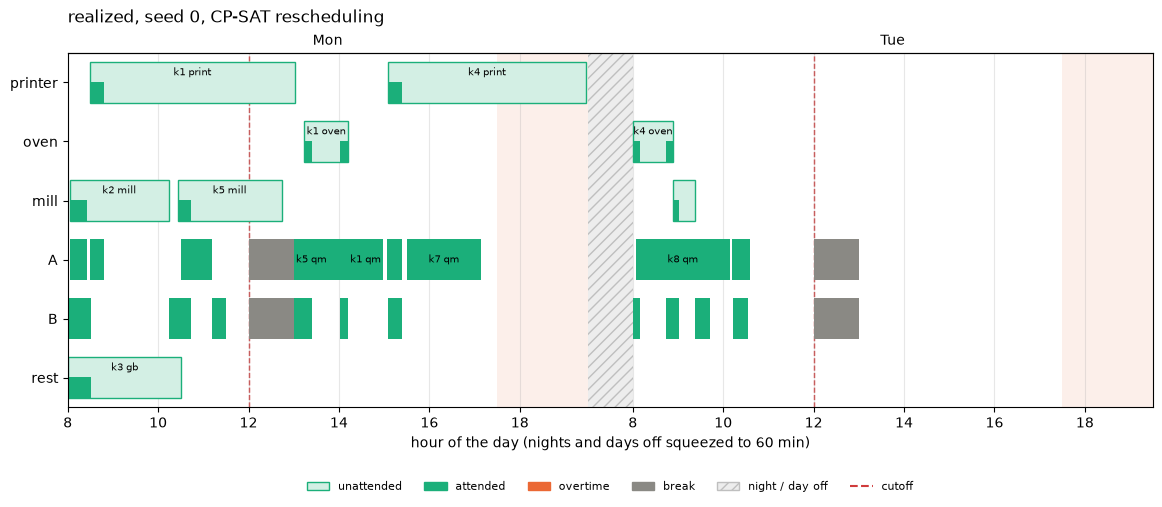

In [9]:
run = results["CP-SAT rescheduling"][0]
plot_shifts(ci, run.schedule, run.breaks, title="realized, seed 0, CP-SAT rescheduling")
plt.show()

## Cutoff slack (O7)

Tardiness strictly first, then the **cutoff slack**: per order the minutes it ends closer than a buffer of 60 minutes
to the cutoff it ships with (`math/04_workers.md` (O7), own modeling after slack and buffer ideas from the
literature), then overtime, breaks and the activity clock (`worker_objective_with_slack(60)`). With planned durations
a plan may otherwise end an order exactly at its cutoff, and the next delay costs a day. First the start plan, then
the same execution comparison with CP-SAT replanning under this objective (the column "short" is the cutoff
shortfall of the realized schedules, summed over the runs).

CP-SAT with cutoff slack: OPTIMAL, levels (0, 20, 30, 0, 920) (days late, shortfall, overtime, breaks, activity clock)
theta objective  days late 0, shortfall 20, overtime 30
cutoff slack     days late 0, shortfall 20, overtime 30


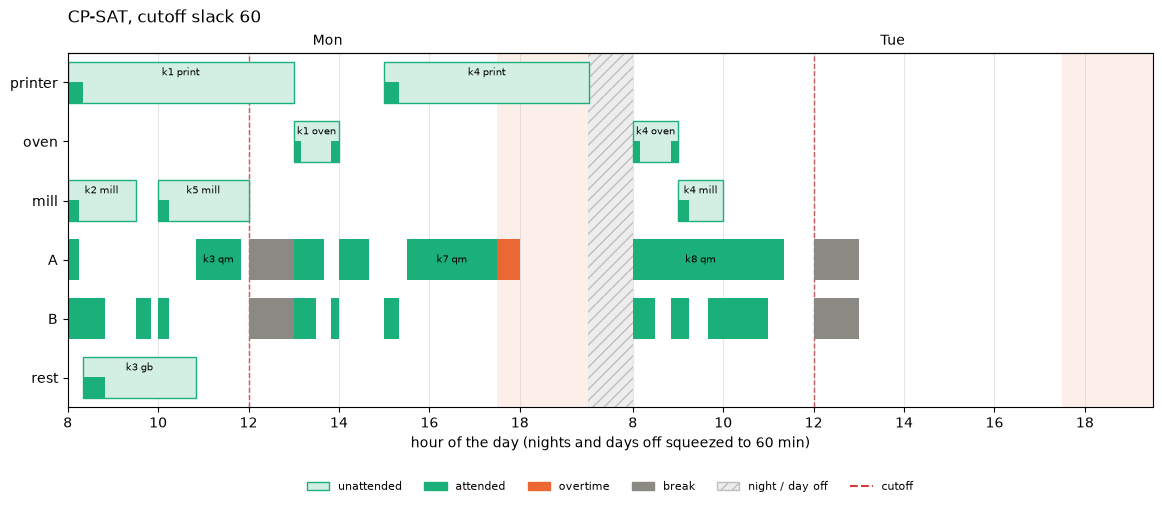

In [10]:
SLACK = worker_objective_with_slack(BUFFER)
cp_slack = solve(ci, SLACK, time_limit=60, workers=1, deterministic_time=20)
print(f"CP-SAT with cutoff slack: {cp_slack.status}, levels {cp_slack.levels} "
      "(days late, shortfall, overtime, breaks, activity clock)")
for name, plan in [("theta objective", cp), ("cutoff slack", cp_slack)]:
    print(f"{name:16} days late {TOTAL_TARDINESS.evaluate(ci, plan.schedule)}, "
          f"shortfall {shortfall.evaluate(ci, plan.schedule)}, overtime {overtime(ci, plan.schedule)}")
plot_shifts(ci, cp_slack.schedule, cp_slack.breaks, title="CP-SAT, cutoff slack 60")
plt.show()

In [11]:
policies_slack = {
    "no planning tool": None,
    "repair only, overtime": ReschedulingPolicy(repair_overtime=True),
    "CP-SAT rescheduling": ReschedulingPolicy(cpsat_planner(time_limit=2, objective=SLACK), **TRIGGERS),
    "CP-SAT + early finish": ReschedulingPolicy(cpsat_planner(time_limit=2, objective=SLACK), **TRIGGERS,
                                                early_finish=10),
    "CP-SAT + early finish + overtime": ReschedulingPolicy(cpsat_planner(time_limit=2, objective=SLACK),
                                                           **TRIGGERS, early_finish=10, repair_overtime=True),
}
results_slack = compare(cp_slack.schedule, cp_slack.breaks, policies_slack)

policy                                days late runs  level 1  short     Cmax    C_act    sum T overtime overruns overstay brk post   spread    swaps      N_C  feasible
no planning tool                         3         2     8.92    530   1678.1    982.4     21.5     35.5      0.0      7.7     15.7     14.7      1.3      0.0      True
                                    days per run: [0, 0, 2, 1, 0, 0, 0, 0, 0, 0], early-finish replans: 0


repair only, overtime                    4         3    10.25    407   1704.3   1008.6     59.6     37.5      0.0      1.0      4.2      4.2      1.2      0.0      True
                                    days per run: [0, 0, 2, 1, 0, 0, 0, 0, 1, 0], early-finish replans: 0


CP-SAT rescheduling                      2         2     6.80    144   1656.9    955.6     16.5     28.8      0.0      2.7      7.0      7.0      0.9     27.0      True
                                    days per run: [0, 0, 1, 1, 0, 0, 0, 0, 0, 0], early-finish replans: 0


CP-SAT + early finish                    2         2     6.85    144   1656.9    955.8     16.5     29.1      0.0      2.6      9.2      9.2      0.5     29.3      True
                                    days per run: [0, 0, 1, 1, 0, 0, 0, 0, 0, 0], early-finish replans: 37


CP-SAT + early finish + overtime         2         2     7.48    144   1656.9    955.8     16.5     32.9      0.0      1.2      9.2      9.2      0.6     17.7      True
                                    days per run: [0, 0, 1, 1, 0, 0, 0, 0, 0, 0], early-finish replans: 37


**Observations** (one toy instance, 10 seeds; own computation, no statistical test):

- **Plans:** CP-SAT books 30 minutes of overtime on Monday (A's QM of k7 until 18:00) and is on time; the best rule
  (MWKR + least load) books no overtime, so k7's QM runs Tuesday after the break and misses Tuesday's cutoff (1 day
  late). With $\theta_O = 1/60$ the 30 minutes are worth half a day: CP-SAT's choice. The activity clock is 920
  against 1190 minutes; the nights do not count while nothing runs.
- **Trade-off:** on the chain the optimum switches from one day late to 90 minutes of overtime between
  $1/\theta_O = 89$ and $91$; at exactly 90 both plans have the same level-1 value and CP-SAT returned the overtime
  plan.
- **Execution:** without a planning tool the factory starts every operation as soon as predecessors, machine and a
  worker allow, in the planned order, and uses overtime up to 19:30 (2 days late over 10 runs). Repair alone adds no
  overtime beyond the plan's: a share that no longer fits moves to the next morning, and the next orders miss their
  cutoff (16 days). **With `repair_overtime`** the repair may use overtime up to the window, as the factory does: 3
  days, 48 minutes overtime per run, close to the factory without a tool.
- **Early-finish trigger** ($\delta_E = 10$): it fires 36 times over the 10 runs, mostly at time points where another
  trigger fires too (2 more reschedulings per run), and CP-SAT returns the same plans: no change in days late (5).
  With this objective an early finish leaves CP-SAT nothing to gain on these seeds; the late days come from plans that
  end orders right at the cutoff (seed 1, protocol (42)), which the cutoff-slack objective (`math/04` (O7)) addresses,
  not shown here. Together with `repair_overtime`: 6 days, less overtime (21.6 against 28.2 minutes per run).
- Replanning every 15 minutes instead of 120 lowers CP-SAT's days late to 4 and gives the lowest level-1 value
  (8.67); the rule plans almost no overtime and is late in every run.
- **Cutoff slack** (buffer 60): from the start the slack plan has the same values as the $\theta_O$ plan (on time,
  shortfall 20, 30 minutes overtime). Under disturbances, CP-SAT replanning with this objective misses 2 cutoffs over
  the 10 runs (seeds 2 and 3, which every policy misses), against 5 with the $\theta_O$ objective; the realized
  shortfall falls from 530 (no tool) to 144 minutes, at 28.8 minutes overtime per run (no tool 35.5). The
  early-finish trigger again fires often (37 times) without changing the days late; with `repair_overtime` as well
  the overtime rises (32.9). Repair alone with overtime misses 4 cutoffs on this start plan (no tool 3):
  in seed 8 the factory gives a blocking packing to the other worker (a swap), and a packing the repair had moved behind B's break no longer counts as
  tight and stays at 13:00 (open point in `math/05` §6).
- All realized schedules pass the checker up to C2 and C14; overruns past the overtime window do not occur; oven
  overstays are rare and short.